<a href="https://colab.research.google.com/github/Bassma-Chemaou/projet6-3d/blob/main/notebooks/01_donnees_3d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/Bassma-Chemaou/projet6-3d.git
%cd projet6-3d
!pip install -q -r requirements.txt
from src.check_env import check_env; check_env()

Cloning into 'projet6-3d'...
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 11 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (11/11), 4.12 KiB | 4.12 MiB/s, done.
/content/projet6-3d
Python : 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39
numpy  : 2.4.6
Graine : 42
torch  : 2.11.0+cu130
GPU    : Tesla T4 | VRAM totale : 15.6 Go
Limite VRAM appliquee : 12 Go (fraction 0.77)


In [2]:
!pip install -q trimesh
import trimesh, numpy as np
print("trimesh", trimesh.__version__, "| numpy", np.__version__)

trimesh 5.2.0 | numpy 2.4.6


In [3]:
import urllib.request, zipfile
from pathlib import Path

CATEGORIES = ["chair", "table", "sofa", "bed"]
RAW = Path("/content/data/raw"); RAW.mkdir(parents=True, exist_ok=True)
zip_path = RAW / "ModelNet10.zip"

if not zip_path.exists():
    urllib.request.urlretrieve(
        "http://3dvision.princeton.edu/projects/2014/3DShapeNets/ModelNet10.zip", zip_path)
print("Taille de l'archive (Mo) :", round(zip_path.stat().st_size / 1e6))

wanted = tuple(f"ModelNet10/{c}/" for c in CATEGORIES)
with zipfile.ZipFile(zip_path) as z:
    members = [m for m in z.namelist() if m.startswith(wanted) and m.endswith(".off")]
    z.extractall(RAW, members)
print(len(members), "fichiers .off extraits\n")

print(f"{'categorie':<10}{'train':>7}{'test':>7}")
for c in CATEGORIES:
    tr = len(list((RAW / "ModelNet10" / c / "train").glob("*.off")))
    te = len(list((RAW / "ModelNet10" / c / "test").glob("*.off")))
    print(f"{c:<10}{tr:>7}{te:>7}")

Taille de l'archive (Mo) : 473
2876 fichiers .off extraits

categorie   train   test
chair         889    100
table         392    100
sofa          680    100
bed           515    100


In [4]:
import numpy as np, trimesh
from pathlib import Path
from scipy.ndimage import binary_closing, binary_fill_holes

SEED, N_POINTS, RES = 42, 2048, 32
MAX_TRAIN_PER_CAT = 400      # garde le total autour de 2 000 objets (consigne du sujet)
VAL_FRACTION = 0.15
OUT = Path("/content/data/processed"); OUT.mkdir(parents=True, exist_ok=True)
ROOT = RAW / "ModelNet10"

def read_off(path):
    """Lecteur .off tolérant (certains fichiers collent 'OFF' aux compteurs)."""
    tokens = open(path).read().split()
    if tokens[0] == "OFF":
        n_v, n_f, pos = int(tokens[1]), int(tokens[2]), 4
    else:
        n_v, n_f, pos = int(tokens[0][3:]), int(tokens[1]), 3
    verts = np.array(tokens[pos:pos + 3 * n_v], dtype=np.float64).reshape(n_v, 3)
    pos += 3 * n_v
    faces = []
    for _ in range(n_f):
        k = int(tokens[pos]); idx = [int(t) for t in tokens[pos + 1:pos + 1 + k]]; pos += 1 + k
        for i in range(1, k - 1):
            faces.append([idx[0], idx[i], idx[i + 1]])
    return trimesh.Trimesh(verts, np.array(faces), process=False)

def normalize(m):
    m = m.copy()
    m.apply_translation(-m.bounding_box.centroid)
    m.apply_scale(1.0 / np.abs(m.vertices).max())
    return m

def to_points(m, seed):
    pts, _ = trimesh.sample.sample_surface(m, N_POINTS, seed=seed)
    return pts.astype(np.float32)

def to_voxels(m, seed):
    dense, _ = trimesh.sample.sample_surface(m, 100_000, seed=seed)
    idx = np.clip(((dense + 1) / 2 * RES).astype(int), 0, RES - 1)
    g = np.zeros((RES, RES, RES), dtype=bool)
    g[idx[:, 0], idx[:, 1], idx[:, 2]] = True
    g = binary_fill_holes(binary_closing(g, iterations=1))
    return g.astype(np.uint8)

def list_files(split):
    return [(f, ci) for ci, c in enumerate(CATEGORIES) for f in sorted((ROOT / c / split).glob("*.off"))]

# validation = 15 % du train (stratifié, graine fixe), après plafonnement par catégorie
rng = np.random.default_rng(SEED)
train_all = list_files("train")
tr_files, val_files = [], []
for ci in range(len(CATEGORIES)):
    cat = [t for t in train_all if t[1] == ci]
    cat = [cat[i] for i in rng.permutation(len(cat))[:MAX_TRAIN_PER_CAT]]
    perm = rng.permutation(len(cat)); n_val = int(round(VAL_FRACTION * len(cat)))
    val_files += [cat[i] for i in perm[:n_val]]
    tr_files += [cat[i] for i in perm[n_val:]]

for tag, files in (("train", tr_files), ("val", val_files), ("test", list_files("test"))):
    P, V, L, N, skipped = [], [], [], [], 0
    for k, (f, lab) in enumerate(files):
        try:
            m = normalize(read_off(f))
            P.append(to_points(m, SEED + k)); V.append(to_voxels(m, SEED + k))
            L.append(lab); N.append(f.stem)
        except Exception as e:
            skipped += 1; print("  [ignoré]", f.name, ":", e)
        if (k + 1) % 250 == 0: print(f"  {tag} : {k+1}/{len(files)}")
    P, V, L, N = np.stack(P), np.stack(V), np.array(L), np.array(N)
    np.save(OUT / f"points_{tag}.npy", P)
    np.savez_compressed(OUT / f"voxels_{tag}.npz", voxels=V)
    np.save(OUT / f"labels_{tag}.npy", L); np.save(OUT / f"names_{tag}.npy", N)
    print(f"{tag} : points {P.shape}, voxels {V.shape}, ignorées {skipped}")
(OUT / "categories.txt").write_text("\n".join(CATEGORIES))

  train : 250/1353
  train : 500/1353
  train : 750/1353
  train : 1000/1353
  train : 1250/1353
train : points (1353, 2048, 3), voxels (1353, 32, 32, 32), ignorées 0
val : points (239, 2048, 3), voxels (239, 32, 32, 32), ignorées 0
  test : 250/400
test : points (400, 2048, 3), voxels (400, 32, 32, 32), ignorées 0


20

       train  val  test
chair    340   60   100
table    333   59   100
sofa     340   60   100
bed      340   60   100
TOTAL   1353  239   400 

Points : min/max = -1.0 1.0 (attendu : dans [-1, 1])
Voxels pleins par forme : min 75 | moyenne 2668 | max 11422


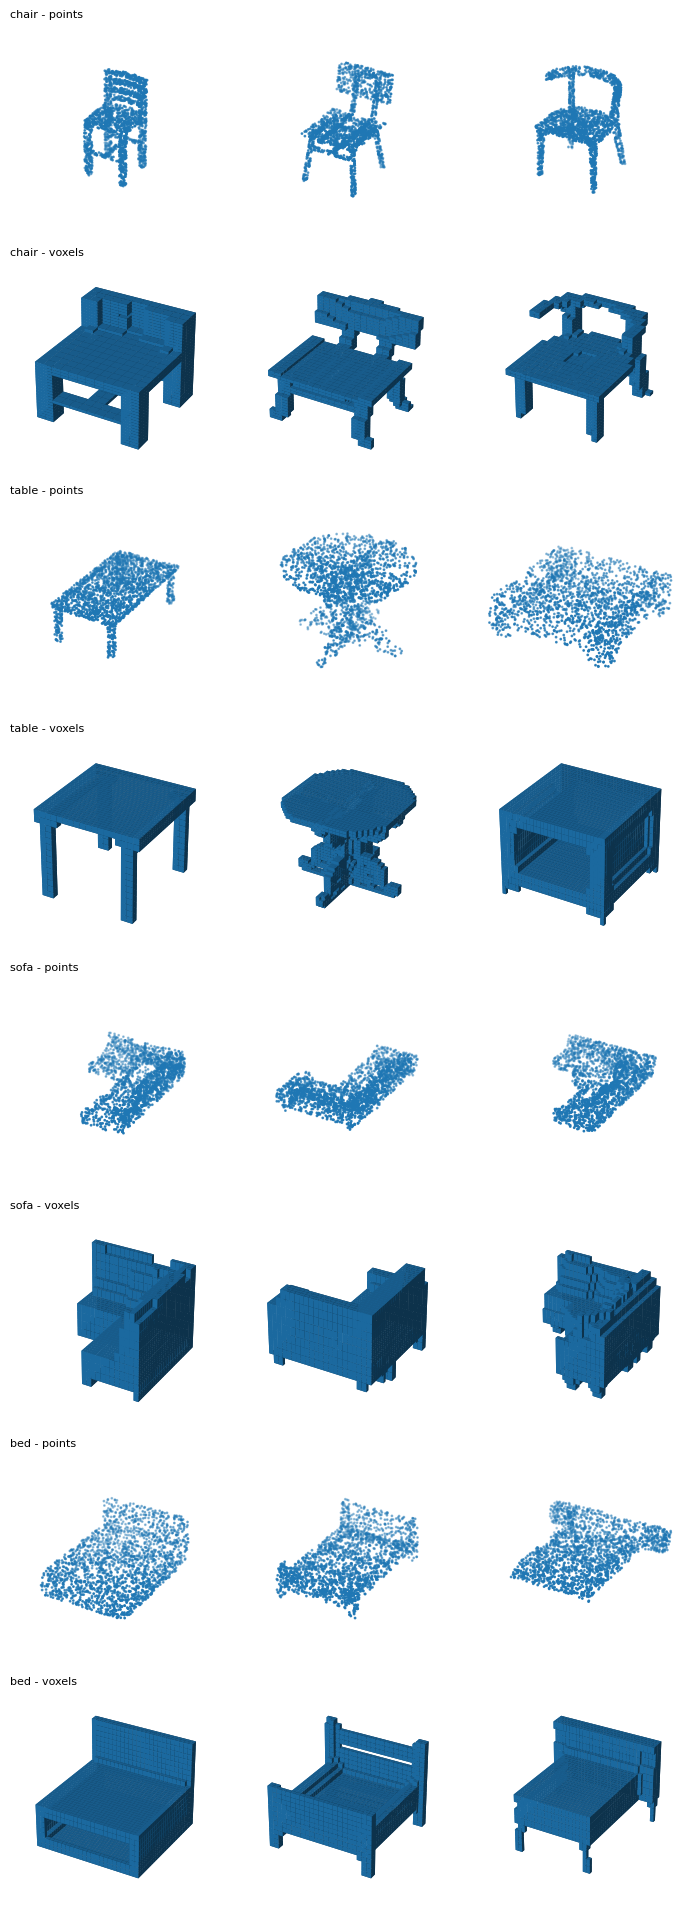

In [5]:
import matplotlib.pyplot as plt, pandas as pd

D = OUT
cats = (D / "categories.txt").read_text().split("\n")
data = {s: dict(points=np.load(D / f"points_{s}.npy"),
                voxels=np.load(D / f"voxels_{s}.npz")["voxels"],
                labels=np.load(D / f"labels_{s}.npy")) for s in ["train", "val", "test"]}

tab = pd.DataFrame({s: [int((data[s]["labels"] == i).sum()) for i in range(len(cats))]
                    for s in data}, index=cats)
tab.loc["TOTAL"] = tab.sum()
print(tab, "\n")

P, V = data["train"]["points"], data["train"]["voxels"]
fill = V.reshape(len(V), -1).sum(1)
print("Points : min/max =", P.min().round(3), P.max().round(3), "(attendu : dans [-1, 1])")
print("Voxels pleins par forme : min", fill.min(), "| moyenne", int(fill.mean()), "| max", fill.max())

per_cat = 3
fig = plt.figure(figsize=(2.4 * per_cat, 2.4 * 2 * len(cats)))
for ci, cat in enumerate(cats):
    idx = np.where(data["train"]["labels"] == ci)[0][:per_cat]
    for j, i in enumerate(idx):
        ax = fig.add_subplot(2 * len(cats), per_cat, 2 * ci * per_cat + j + 1, projection="3d")
        ax.scatter(P[i, :, 0], P[i, :, 1], P[i, :, 2], s=1)
        ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1); ax.set_axis_off()
        if j == 0: ax.set_title(f"{cat} - points", fontsize=8, loc="left")
        ax = fig.add_subplot(2 * len(cats), per_cat, (2 * ci + 1) * per_cat + j + 1, projection="3d")
        ax.voxels(V[i].astype(bool)); ax.set_axis_off()
        if j == 0: ax.set_title(f"{cat} - voxels", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

In [6]:
names = np.load(D / "names_train.npy")
for i in np.argsort(fill)[:5]:
    print(names[i], "->", fill[i], "voxels")

bed_0173 -> 75 voxels
table_0112 -> 255 voxels
table_0116 -> 400 voxels
table_0323 -> 474 voxels
table_0236 -> 475 voxels


In [7]:
import os
from google.colab import drive, files

os.makedirs("/content/results", exist_ok=True)
fig.savefig("/content/results/controle_donnees.png", dpi=130, bbox_inches="tight")
tab.to_csv("/content/results/effectifs.csv")

drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/projet6-3d
!cp -r /content/data/processed /content/drive/MyDrive/projet6-3d/
!du -sh /content/drive/MyDrive/projet6-3d/processed

files.download("/content/results/controle_donnees.png")
files.download("/content/results/effectifs.csv")

Mounted at /content/drive
48M	/content/drive/MyDrive/projet6-3d/processed


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>